In [1]:
import numpy as np 
from utils import *

# Full Network

I have written a neural network's layer in utils.py. To the best of my knowledge, the functions implemented there correctly track the math of the output and derivatives of a single neural network. Here, I will try to expand this and implement a fully connected NN with an arbitrary number of layers. 

In [3]:
class network:

    def __init__(self, spec, activation=[sigmoid], del_activation=[del_sigmoid]):
        ''' 
        Initialization of a neural network. spec is a list of numbers specifying the size of each layer. 
        Start from the input layer and finish with the output layer.

        An activation is a layer's quality. Should not be a network's attribute.

        MODIFICATION: Allow for layers with different activations.
        '''
        self.layers = []

        assert len(activation) == len(del_activation), "Must provide same number of activations and derivatives"

        if len(activation) > 1:
            assert len(spec) == len(activation) + 2, 'Input and output layer are not activated'

        for i in range(len(spec) - 1):

            # Extract input and output sizes of the i-th layer
            n_in = spec[i]
            n_out = spec[i + 1]

            # Output layer: no activation
            if i == len(spec) - 2:
                act = id  
                del_act = del_id

            # Hidden layers 
            elif len(activation) == 1:
                act = activation[0]
                del_act = del_activation[0]

            else:
                act = activation[i]
                del_act = del_activation[i]

            self.layers.append(
                layer(n_in, n_out, 
                        activation=act,
                        del_activation=del_act)
                        )

    def __call__(self, x, return_args=False): 
        '''
        Network's forward pass. Is there any way around sequentiallity? Or do I necessarilly need to use for loops
        x has a shape (n_in, d). We wish to pass multiple inputs through the network at once. We save intermediate outputs
        '''
        
        # Assert input's correct size
        layers = self.layers
        L0 = layers[0]
        n_in = L0.dims[1]
        d = x.shape[1]
        assert x.shape[0] == n_in, 'input size is incorrect'

        # Initialize array to save intermediate outputs
        zs = []
        args = []

        # Loop over each layer's output
        for i in range(len(layers)):

            # Edge case: first layer takes a data-point as input
            if i == 0:
                z, arg = layers[i](x) # (n_1, d)
                assert z.shape[0] == layers[i].dims[0], 'output of first layer has incorrect size'
                zs.append(z)
                args.append(arg)
                continue

            # For the rest of the network, the input of a layer is the output of the previous layer
            z, arg = self.layers[i](z) # (n_i, d)

            zs.append(z)
            args.append(arg)

        # Return the full intermediate outputs array. The final output is just zs[-1]
        if return_args==True:
            return zs, args
        
        return zs

    def MSE_loss(self, data):
        ''' 
        Loss function of the network with respect to a set of data.  
        Data is of the form (x, y), where x is an array of shape (n_in, d) and
        y has the shape (n_out, d)
        '''

        # Get Network's forward pass
        x = data[0] # (n_in, d)
        y = data[1] # (n_out, d)
        d = x.shape[1]
        layers = self.layers

        # Assert the output has correct size
        Lout = layers[-1]
        n_out = Lout.dims[0]
        assert n_out == y.shape[0], 'size of last layers output and the size of data targets dont match'
        assert d == y.shape[1], 'number of inputs and targets in the dataset dont match'

        # Network's forward pass
        zs = self(x)
        C = zs[-1] # (n_out, d)

        # Compute residuals 
        res = y - C # (n_out, d)
        mags = np.linalg.norm(res, axis=0) ** 2 # (d,)

        # Compute loss
        loss = 0.5 * np.mean(mags) # Just a number 
        return loss


    def grad_loss(self, data):
        ''' 
        Computes the partial derivatives of the loss function with respect to all parameters in the network. 
        Returns an two arrays filled with the partial derivatives with respect to each layer's weight matrix and bias vector
        shape (del_W, del_b) where del_W is a list of matrices and del_b is a list of vectors.
        '''
        # Get data
        x = data[0]
        y = data[1]
        d = x.shape[1]
        layers = self.layers
        

        # compute network's forward and residuals
        zs = self(x)
        res = y - zs[-1] # (n_out, d)

        # initialize lists to store gradients
        del_W = []
        del_b = []

        # if its a single layer, use gradients from before
        if len(layers) == 1:
            dW, db = layers[0].grad_loss(data)
            del_W.append(dW)
            del_b.append(db)
            return del_W, del_b  

        # Iterate over layers, start with the last layer
        for i in range(len(layers)):

            # Invert counting order
            j = len(layers) - 1 - i

            # layer output and params
            z = zs[j] # (n_curr, d)
            (n_curr, n_prev) = layers[j].dims 
            assert z.shape[0] == n_curr, 'wrong layer output dimensions'

            # Edge case: don't compute jacobian for the output layer
            if j == len(layers) - 1:

                # Output layer params
                n_out = n_curr
                n_sec_to_last = n_prev
                
                # Use previous layer code to compute gradient.  
                data_out = (zs[j - 1], y) 
                del_W_out, del_b_out = layers[j].grad_loss(data_out) 
                del_W.append(del_W_out) # (n_out, n_prev)
                del_b.append(del_b_out) # (n_out,)

                # Initial jacobian
                H = layers[j].jacobian(zs[j - 1]) # (n_out, n_prev, d)

                continue

            # assert shape of current jacobian
            assert H.shape == (n_out, n_curr, d), 'wrong jacobian shape'
 
            # activation derivative and forward derivative 
            del_phi = np.reshape(z * (1 - z), (1, n_curr, d)) # (1, n_curr, d)
            mult = H * del_phi # (n_out, n_curr, d) 

            # build partial derivatives for bias 
            inner_b = np.einsum('ij, ikj -> kj', res, mult) # (n_curr, d)
            del_b_curr = - np.mean(inner_b, axis=1) # (n_curr,)
            del_b_curr = np.reshape(del_b_curr, (n_curr, 1))

            # build partial derivatives for weights, edge case for first layer 
            if j == 0:
                z_prev = x # (n_in, d)
            else:
                z_prev = zs[j - 1] # (n_prev, d)

            # multiply forward derivative with previous output
            del_W_curr = -(inner_b @ z_prev.T) / d   # (n_curr, n_prev)

            # Store partial derivatives
            del_W.append(del_W_curr)
            del_b.append(del_b_curr)
    
            if j > 0:
                J = layers[j].jacobian(z_prev)                 # (n_curr, n_prev, d)
                H = np.einsum('ijk, jnk -> ink', H, J)         # (n_out, n_prev, d)

        # Reverse order of lists
        del_W = del_W[::-1]
        del_b = del_b[::-1]

        return del_W, del_b

    def CE_loss(self, data):
        ''' 
        Computes the CE loss of the dataset. From the output of the network, we can use the resulting logits under a softmax to get
        a probability distribution. We use this distribution to compute the average CE loss, that is, the negative logprob of having correctly classified
        each label. 

        data = (x, y) where x is (n_in, d) and y has shape (n_out, d) one-hot vectors
        '''
        x = data[0]
        y = data[1]
        d = x.shape[1]

        # Forward pass of the NN - logits
        zs, args = self(x, return_args=True)
        logits = args[-1] # (n_out, d)

        # Compute CE loss using logsumexp form 
        from scipy.special import logsumexp

        y_labels = onehot_to_labels(y).astype(int) # (d,)
        sample_loss = -logits[y_labels, np.arange(d)] + logsumexp(logits, axis=0) # (d,)

        return np.mean(sample_loss) 


    def backprop(self, data, loss="MSE"):
        ''' 
        Computation of the loss' gradient using a (hopefully) faster algorithm. Looks promising. No need for computing huge jacobians.
        We only pass one vector from layer to layer and update via matrix multiplication with the weight matrix. 

        data = (x, y) where x has shape (n_in, d) and y has shape (n_out, d)
        '''
        x = data[0]
        y = data[1]
        d = x.shape[1]
        layers = self.layers

        # Prepare lists to store each layer's partial derivatives
        del_W = []
        del_b = []

        # Compute network's output and residual
        zs, args = self(x, return_args=True) 
        L = len(zs)

        if loss=="MSE":
            res = y - zs[-1] # (n_out, d)

        if loss=="CE":
            # compute softmax of output 
            from scipy.special import softmax
            p = softmax(args[-1], axis=0) # (n_out, d)
            res = y - p # (n_out, d) 

        # Iterate over layers backwards
        for i in range(L):

            # To count backwards, we use j from L-1 to 0 (L-th layer to 1-st layer)
            j = L - 1 - i

            # Edge case, input layer
            if j == 0:
                z_prev = x
            else:
                z_prev = zs[j - 1]
            
            # Extract output of previous layer and current layer's arg
            n_prev = z_prev.shape[0]
            arg = args[j] # (n_curr, d)
            n_curr = arg.shape[0]

            # At the output layer, construct the first g
            if j == L - 1:

                # Get first g and compute partial derivatives at the output layer
                g = layers[j].del_activation(arg) * res # (n_out, d)
                gr = np.reshape(g, (n_curr, 1, d)) # (n_out, 1, d)
                
                db = - np.mean(gr, axis=2) # (n_out, 1) 
                dW = - g @ z_prev.T / d

                del_b.append(db)
                del_W.append(dW)

                h = (layers[j].W).T @ g
                
                continue

            g = layers[j].del_activation(arg) * h # (n_curr, d)
            gr = np.reshape(g, (n_curr,1,d)) # (n_curr, 1, d)

            # Use g to get partial derivatives
            db = - np.mean(gr, axis=2) # (n_out, 1) 
            dW = - g @ z_prev.T / d # (n_curr, n_)

            del_b.append(db)
            del_W.append(dW)
            
            if j > 0:
                # if we are at the input layer, there is no need to recompute. First weight matrix never appears. Interesting. 
                h = (layers[j].W).T @ g
        
        del_W = del_W[::-1]
        del_b = del_b[::-1]

        return del_W, del_b



                



        



        

NN class tests

In [4]:
# Consider a network with a single layer. Outputs should match outputs of the single layer as before

spec = [2, 2]

NN = network(spec)
layers = NN.layers

layers[0].W = np.array([[1, -1],
                        [-1, 1]])

layers[0].b = np.array([[0],
                        [0]])
print('Layer weight matrix', NN.layers[0].W)
print('Layer bias', NN.layers[0].b)

x = np.array([[1, 0],
              [1, 0]])

y = np.array([[0.5, 0.5],
              [0.5, 0.5]])

zs = NN(x)
loss = NN.MSE_loss((x, y))
del_W, del_b = NN.grad_loss((x,y))
print('layer output', zs) # (0.5, 0.5)
print('layer loss', loss) # 0

Layer weight matrix [[ 1 -1]
 [-1  1]]
Layer bias [[0]
 [0]]
layer output [array([[0, 0],
       [0, 0]])]
layer loss 0.25000000000000006


Tests for multi-layered network

In [5]:
spec2 = [2, 3, 2]

NN2 = network(spec2)

for i in range(2):
    l = NN2.layers[i]
    print('dimensions of the', i, '-th layer', l.dims)
    # (3, 2), (2, 3)

zs = NN2(x)
loss = NN2.MSE_loss((x, y))
print('layer output', zs) 
print('layer loss', loss)

H = np.array([[1, 2],
              [1, 2],
              [1, 2]]) # (3, 2)

H_r = np.reshape(H, (3, 2, 1))

phi = np.array([[1, 3],
                [2, 4]]) # (2, 2)

phi_r = np.reshape(phi, (1, 2, 2))

resaltalt = H_r * phi_r # (3, 2, 2)

print('tensordor result:', resaltalt) # Expect [[[1, 3], [4, 8]]], [1, 4], [1, 4]]
print('single matrices', resaltalt[:,:,1])

del_W, del_b = NN2.grad_loss((x,y))

dimensions of the 0 -th layer (3, 2)
dimensions of the 1 -th layer (2, 3)
layer output [array([[0.21786614, 0.5       ],
       [0.20696338, 0.5       ],
       [0.14397067, 0.5       ]]), array([[-0.51376293, -1.32922518],
       [ 0.28675866,  0.75089298]])]
layer loss 1.120549795455204
tensordor result: [[[1 3]
  [4 8]]

 [[1 3]
  [4 8]]

 [[1 3]
  [4 8]]]
single matrices [[3 8]
 [3 8]
 [3 8]]


The gradient seems to be working correctly. Let's try with some training

In [6]:
def train(NN, train_data, val_data, epochs=20, minibatch_size=50, eta=0.1, verbose=True):
    '''
    Training function for a single layer using SGD. Must include a test/train split. 

    - L is a layer as defined above. Initial weights and biases already initialized.
    - training_data is 
    - epochs is the number of times that the training loop will visit the full training set 
    - minibatch_size is the size of the minibatch. *Same batching every epoch* TO DO: randomize batches
    - eta is the learning rate

    '''
    # Compute initial training loss
    loss0 = NN.CE_loss(train_data)
    train_losses = np.zeros(epochs)
    val_losses = np.zeros(epochs)
    print('Initial Training Loss', loss0)

    x_train = train_data[0]
    y_train = train_data[1]

    # Compute number of minibatches
    d_train = x_train.shape[1]
    n_batches = int(d_train / minibatch_size)
    
    for e in tqdm(range(epochs)):

        for n in range(n_batches):

            # Organize batch's training samples for SGD
            # Edge case: last batch may not be big enough. Avoid slicing error
            if n == n_batches - 1:
                x_batch = x_train[:, n * minibatch_size :]
                y_batch = y_train[:, n * minibatch_size :]
            else:
                x_batch = x_train[:, n * minibatch_size : (n+1) * minibatch_size]
                y_batch = y_train[:, n * minibatch_size: (n+1) * minibatch_size]

            data_batch = (x_batch, y_batch)

            # Compute gradients   
            del_W, del_b = NN.backprop(data_batch, loss="CE")

            # Iterate over layers and update parameters
            for i in range(len(NN.layers)):
                
                # Extract layer gradients
                del_Wi, del_bi = del_W[i], del_b[i]
                
                # Gradient step
                NN.layers[i].W = NN.layers[i].W - eta * del_Wi
                NN.layers[i].b = NN.layers[i].b - eta * del_bi


        # Recompute loss at the end of the epoch
        loss = NN.MSE_loss(train_data)
        loss = NN.CE_loss(train_data)
        val_loss = NN.MSE_loss(val_data)
        val_loss = NN.CE_loss(val_data)
        train_losses[e] = loss
        val_losses[e] = val_loss

        if verbose==True:
            print('Loss at epoch e =', e, ':', loss)

    return NN, train_losses, val_losses


Having a training code, we can start with a trial run. Preprocess data

(50000, 784) (50000,)


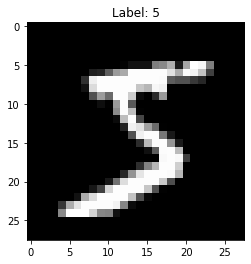

In [7]:
import pickle
import gzip

with gzip.open('neural-networks-and-deep-learning-master/data/mnist.pkl.gz', 'rb') as f:
    training_data, validation_data, test_data = pickle.load(f, encoding='latin1')

print(training_data[0].shape, training_data[1].shape)   # (50000, 784) (50000,)

first_image = training_data[0][0]
first_label = training_data[1][0]

# Reshape the first image to 28x28 pixels
image = first_image.reshape(28, 28)

# Display the image
plt.imshow(image, cmap='gray')
plt.title(f"Label: {first_label}")
plt.show()


In [8]:
# Extract labels and training images from training_data
y_labels = training_data[1]
x_train = training_data[0].T

# Extract validation data
y_labels_val = validation_data[1]
x_val = validation_data[0].T

print(x_train.shape) # (728, 50000)
d = len(y_labels)

y_train = labels_to_onehot(y_labels)
y_val = labels_to_onehot(y_labels_val)


# Organize training data
train_data = (x_train, y_train)
val_data = (x_val, y_val)

(784, 50000)


Test Training run

Initial Training Loss 2.3834322809024546


  2%|▏         | 1/50 [00:02<02:05,  2.56s/it]

Loss at epoch e = 0 : 0.412997399276558


  4%|▍         | 2/50 [00:05<02:11,  2.73s/it]

Loss at epoch e = 1 : 0.31933002258234466


  6%|▌         | 3/50 [00:08<02:06,  2.69s/it]

... (91 outputs left out)

 98%|█████████▊| 49/50 [02:05<00:02,  2.72s/it]

Loss at epoch e = 48 : 0.033343093806039226


100%|██████████| 50/50 [02:07<00:00,  2.55s/it]

Loss at epoch e = 49 : 0.03237356363584958


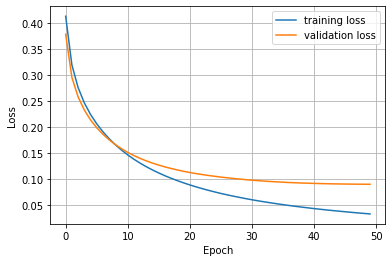

In [9]:
# Initialize a neural Network

spec = [784, 128, 64, 10]
acts = [ReLU, ReLU]
del_acts = [del_ReLU, del_ReLU]

NN = network(spec, activation=acts, del_activation=del_acts)

epochs=50
eta=0.01
minibatch_size = 50
NN, train_losses, val_losses = train(NN, train_data, val_data, epochs=epochs, minibatch_size=minibatch_size, eta=eta, verbose=True)

plot_loss(train_losses, val_losses)

In [11]:
# Extract test set 
x_test = test_data[0].T
y_test = test_data[1]

# Compute predicted labels on the test set
pred_onehot = NN(x_test)[-1]
pred_labels = onehot_to_labels(pred_onehot)

print('labels shape', pred_labels.shape)

accuracy = np.mean(y_test == pred_labels)
print('accuracy on the test set', accuracy)

accuracy = compute_accuracy(NN, x_test, y_test)
print(accuracy)

labels shape (10000,)
accuracy on the test set 0.9738
0.9738


Initial Training Loss 2.335643620793854


100%|██████████| 50/50 [27:51<00:00, 33.42s/it]   


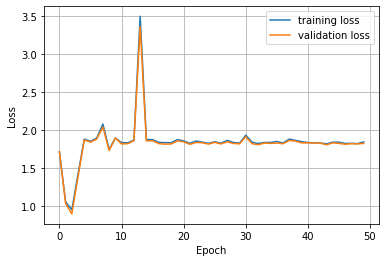

accuracy for lr = 1 : 0.1974
Initial Training Loss 2.335643620793854


100%|██████████| 50/50 [02:09<00:00,  2.59s/it]


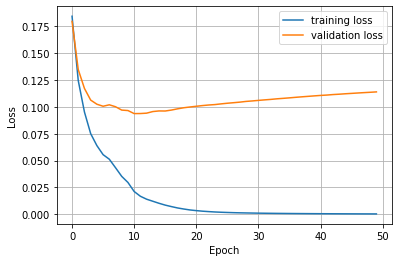

accuracy for lr = 0.1 : 0.9792
Initial Training Loss 2.335643620793854


100%|██████████| 50/50 [02:07<00:00,  2.55s/it]


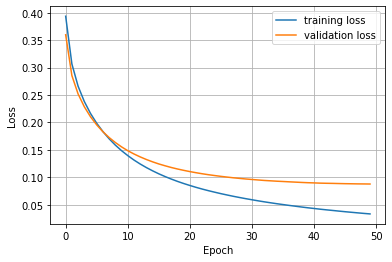

accuracy for lr = 0.01 : 0.9763
Initial Training Loss 2.335643620793854


100%|██████████| 50/50 [02:07<00:00,  2.54s/it]


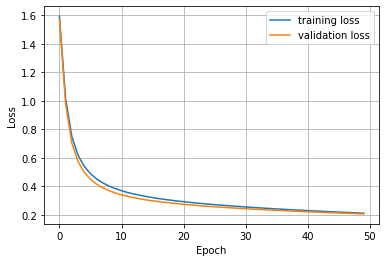

accuracy for lr = 0.001 : 0.9415
[0.1974 0.9792 0.9763 0.9415]


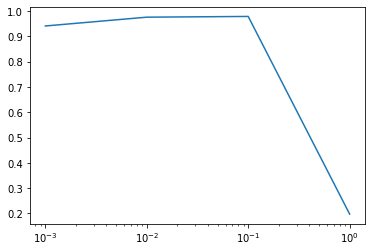

In [12]:
import copy
epochs = 50
etas = [1, 0.1, 0.01, 0.001]
accuracies = np.zeros(4)

# Same initialization -> Same initial condition
NN = network([784, 128, 64, 10], activation=acts, del_activation=del_acts)

for i in range(4):
    Li = copy.deepcopy(NN) 
    Li, train_losses, val_losses = train(Li, train_data, val_data, epochs=50, minibatch_size=50, eta=etas[i], verbose=False)
    plot_loss(train_losses, val_losses)
    accuracies[i] = compute_accuracy(Li, x_val, y_labels_val)
    print('accuracy for lr =', etas[i], ':', accuracies[i])

print(accuracies)

plt.figure()
plt.semilogx(etas, accuracies)

Now we can experiment with the size of the hidden layer

Initial Training Loss 2.3877696890889135


100%|██████████| 50/50 [01:11<00:00,  1.44s/it]


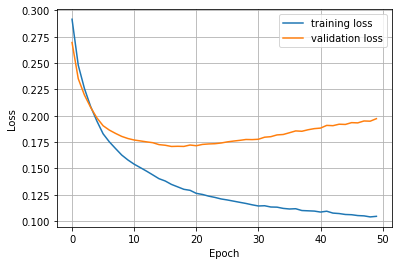

accuracy for hidden size = 16 : 0.9505
Initial Training Loss 2.413957568661627


100%|██████████| 50/50 [01:16<00:00,  1.52s/it]


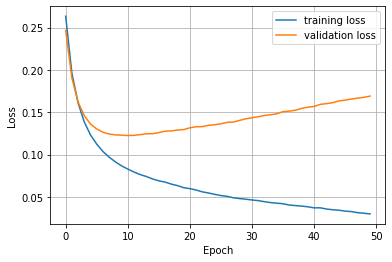

accuracy for hidden size = 32 : 0.9646
Initial Training Loss 2.41727146320565


100%|██████████| 50/50 [01:26<00:00,  1.73s/it]


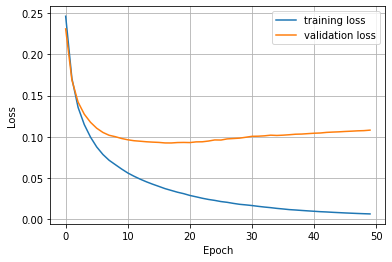

accuracy for hidden size = 64 : 0.9756
Initial Training Loss 2.3735070598082864


100%|██████████| 50/50 [01:57<00:00,  2.36s/it]


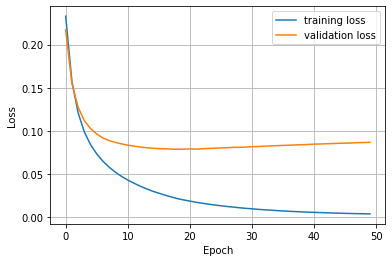

accuracy for hidden size = 128 : 0.9783
Initial Training Loss 2.459550801669497


100%|██████████| 50/50 [03:20<00:00,  4.01s/it]


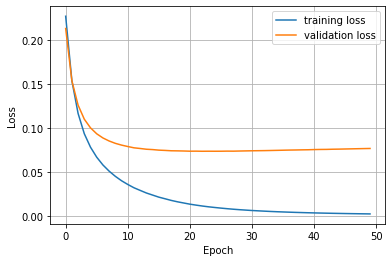

accuracy for hidden size = 256 : 0.9802
Initial Training Loss 2.536403592310612


100%|██████████| 50/50 [05:11<00:00,  6.22s/it]


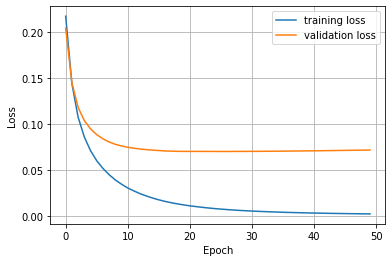

accuracy for hidden size = 512 : 0.9817
[0.9505 0.9646 0.9756 0.9783 0.9802 0.9817]


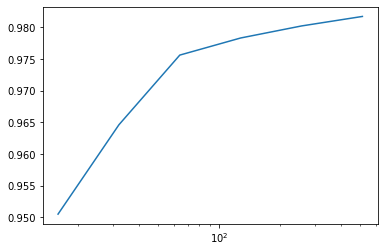

In [23]:
import copy
epochs = 50
hiddens = [16, 32, 64, 128, 256, 512]
networks = []
acts = [ReLU]
del_acts = [del_ReLU] 

# Careful: not every network is equally initialized! Bad for an experiment
for h in hiddens:
    net = network([784, h, 10], activation=acts, del_activation=del_acts)
    networks.append(net)

accuracies = np.zeros(6)

for i in range(6):
    h = hiddens[i]
    net_h = networks[i]
    net_h, train_losses, val_losses = train(net_h, train_data, val_data, epochs=50, minibatch_size=50, eta=0.1, verbose=False)
    plot_loss(train_losses, val_losses)
    accuracies[i] = compute_accuracy(net_h, x_val, y_labels_val)
    networks[i] = net_h
    print('accuracy for hidden size =', h, ':', accuracies[i])

print(accuracies)

plt.figure()
plt.semilogx(hiddens, accuracies)

Save weights of best-performing network. 

In [24]:
best_nn = networks[-1]

np.savez(
    "best_weights.npz",
    **{
        f"W{i}": layer.W
        for i, layer in enumerate(best_nn.layers)
    },
    **{
        f"b{i}": layer.b
        for i, layer in enumerate(best_nn.layers)
    }
)